__Project Objective__ :The objective of this project is to analyze IMDb movie data using Python to identify highly rated movies, popular genres, top directors, and highest-grossing movies. It also aims to understand the relationship between IMDb ratings, audience votes, movie runtime, and gross income to identify patterns in movie performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

__Loading the datasets__

In [2]:
basic=pd.read_csv("imdb_movies_basic.csv")
business=pd.read_csv("imdb_movies_business.csv")

__DATA CLEANING__

Understanding the datasets

In [3]:
basic.head()

,movie_name,release_year,runtime,genre,IMDB_rating,meta_score,Director
0,The Last Journey,2018.0,146.0,Romance,6.7,69.0,Peter Adams
1,The Last Legacy,2004.0,176.0,War,5.8,55.0,Unknown
2,The Last Promise,1997.0,131.0,Romance,7.5,71.0,Christopher Miller
3,The Last Dream,2010.0,114.0,Romance,6.7,54.0,Robert Wilson
4,The Last Empire,2008.0,80.0,Horror,8.1,80.0,Mark Robinson


In [4]:
basic.shape

(600, 7)

In [5]:
basic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   movie_name    600 non-null    object 
 1   release_year  592 non-null    float64
 2   runtime       590 non-null    float64
 3   genre         593 non-null    object 
 4   IMDB_rating   592 non-null    float64
 5   meta_score    585 non-null    float64
 6   Director      588 non-null    object 
dtypes: float64(4), object(3)
memory usage: 32.9+ KB


In [6]:
basic.describe()

,release_year,runtime,IMDB_rating,meta_score
count,592.000000,590.000000,592.000000,585.000000
mean,2007.717905,127.659322,7.089358,76.018803
std,10.456411,25.357362,0.932931,14.145695
min,1990.000000,80.000000,4.800000,31.000000
25%,1998.000000,111.000000,6.500000,67.000000
50%,2008.000000,128.000000,7.100000,76.000000
75%,2017.000000,144.000000,7.725000,87.000000
max,2024.000000,204.000000,9.400000,98.000000


In [7]:
business.head()

,movie_name,Stars,no_of_votes,gross_income,hit/flop
0,The Last Journey,"Daniel Lewis, James Wilson, Alex Harris, David...",24557.0,870234.0,Flop
1,The Last Legacy,"John Davis, Michael Johnson, Olivia Moore, Emi...",77256.0,1900203.0,Flop
2,The Last Promise,"Emma Taylor, Michael Johnson, Olivia Moore, Sa...",14461.0,500000.0,Flop
3,The Last Dream,"Daniel Brown, Chris Anderson, Anna Davis, Chri...",101286.0,1838941.0,Flop
4,The Last Empire,"Daniel Lewis, Sarah Williams, Olivia Moore, So...",15595.0,500000.0,Flop


In [8]:
business.shape

(600, 5)

In [9]:
business.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   movie_name    600 non-null    object 
 1   Stars         588 non-null    object 
 2   no_of_votes   590 non-null    float64
 3   gross_income  582 non-null    float64
 4   hit/flop      592 non-null    object 
dtypes: float64(2), object(3)
memory usage: 23.6+ KB


In [10]:
business.describe()

,no_of_votes,gross_income
count,5.900000e+02,5.820000e+02
mean,1.287567e+05,4.272208e+06
std,2.161108e+05,8.392771e+06
min,5.493000e+03,5.000000e+05
25%,4.144975e+04,1.097107e+06
50%,7.365800e+04,2.213150e+06
75%,1.405282e+05,4.278338e+06
max,3.500000e+06,1.183560e+08


__Checking the  missing values__

In [11]:
basic.isnull().sum()

movie_name       0
release_year     8
runtime         10
genre            7
IMDB_rating      8
meta_score      15
Director        12
dtype: int64

In [12]:
business.isnull().sum()

movie_name       0
Stars           12
no_of_votes     10
gross_income    18
hit/flop         8
dtype: int64

In [13]:
#checking for thr row which contains null values
missing_rows=basic[basic.isnull().any(axis=1)]
missing_rows

,movie_name,release_year,runtime,genre,IMDB_rating,meta_score,Director
9,The Last Hope,2013.0,131.0,Thriller,8.5,NaN,Kevin Lewis
11,The Last Escape,NaN,160.0,Horror,9.4,93.0,Brian Taylor
15,The Last Night,1991.0,155.0,Thriller,5.7,76.0,NaN
54,Silent Road,NaN,170.0,Thriller,7.6,76.0,William Scott
55,Silent Night,1997.0,131.0,Romance,7.2,73.0,NaN
57,Silent Past,2012.0,105.0,NaN,5.9,58.0,Anthony Wright
73,Hidden Kingdom,2013.0,NaN,Romance,6.6,66.0,Jonathan Moore
75,Hidden Night,2006.0,166.0,Adventure,NaN,68.0,Edward Harris
80,Broken Journey,1994.0,131.0,Comedy,5.2,NaN,Anthony Wright
96,Broken Future,2003.0,114.0,Action,6.7,NaN,Brian Taylor


In [14]:
#calculating the percentage of null values
basic.isnull().mean().mul(100).round(2)

movie_name      0.00
release_year    1.33
runtime         1.67
genre           1.17
IMDB_rating     1.33
meta_score      2.50
Director        2.00
dtype: float64

In [15]:
business.isnull().mean().mul(100).round(2)

movie_name      0.00
Stars           2.00
no_of_votes     1.67
gross_income    3.00
hit/flop        1.33
dtype: float64

In [16]:
#filling the null values
basic["runtime"].fillna(basic["runtime"].mean(), inplace=True)
basic["IMDB_rating"].fillna(basic["IMDB_rating"].mean(), inplace=True)
basic["meta_score"].fillna(basic["meta_score"].mean(), inplace=True)
basic["Director"].fillna('unknown',inplace=True)

C:\Users\Harshitha\AppData\Local\Temp\ipykernel_11612\672041740.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  basic["runtime"].fillna(basic["runtime"].mean(), inplace=True)
C:\Users\Harshitha\AppData\Local\Temp\ipykernel_11612\672041740.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves

In [17]:
basic.isnull().sum()

movie_name      0
release_year    8
runtime         0
genre           7
IMDB_rating     0
meta_score      0
Director        0
dtype: int64

In [18]:
business["Stars"].fillna('unknown', inplace=True)
business["no_of_votes"].fillna(business["no_of_votes"].mean(), inplace=True)
business["gross_income"].fillna(business["gross_income"].mean(), inplace=True)

C:\Users\Harshitha\AppData\Local\Temp\ipykernel_11612\1731925468.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  business["Stars"].fillna('unknown', inplace=True)
C:\Users\Harshitha\AppData\Local\Temp\ipykernel_11612\1731925468.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

In [19]:
business.isnull().sum()

movie_name      0
Stars           0
no_of_votes     0
gross_income    0
hit/flop        8
dtype: int64

__Checking the duplicated values__

In [20]:
basic.duplicated().sum()

np.int64(0)

In [21]:
business.duplicated().sum()

np.int64(0)

In [22]:
#merging the two datasets
merged_data = pd.merge(
    basic,
    business,
    on="movie_name",
    how="inner"
)

In [23]:
#checking the merged data
merged_data.head()

,movie_name,release_year,runtime,genre,IMDB_rating,meta_score,Director,Stars,no_of_votes,gross_income,hit/flop
0,The Last Journey,2018.0,146.0,Romance,6.7,69.0,Peter Adams,"Daniel Lewis, James Wilson, Alex Harris, David...",24557.0,870234.0,Flop
1,The Last Legacy,2004.0,176.0,War,5.8,55.0,Unknown,"John Davis, Michael Johnson, Olivia Moore, Emi...",77256.0,1900203.0,Flop
2,The Last Promise,1997.0,131.0,Romance,7.5,71.0,Christopher Miller,"Emma Taylor, Michael Johnson, Olivia Moore, Sa...",14461.0,500000.0,Flop
3,The Last Dream,2010.0,114.0,Romance,6.7,54.0,Robert Wilson,"Daniel Brown, Chris Anderson, Anna Davis, Chri...",101286.0,1838941.0,Flop
4,The Last Empire,2008.0,80.0,Horror,8.1,80.0,Mark Robinson,"Daniel Lewis, Sarah Williams, Olivia Moore, So...",15595.0,500000.0,Flop


In [24]:
merged_data.shape

(600, 11)

In [25]:
merged_data.columns

Index(['movie_name', 'release_year', 'runtime', 'genre', 'IMDB_rating',
       'meta_score', 'Director', 'Stars', 'no_of_votes', 'gross_income',
       'hit/flop'],
      dtype='object')

In [26]:
merged_data.isnull().sum()

movie_name      0
release_year    8
runtime         0
genre           7
IMDB_rating     0
meta_score      0
Director        0
Stars           0
no_of_votes     0
gross_income    0
hit/flop        8
dtype: int64

In [27]:
merged_data.duplicated().sum()

np.int64(0)

__Saving the merged data__

In [28]:
merged_data.to_csv('imdb_movies_merged.csv', index=False)

In [29]:
#loading the merged data
merged_data=pd.read_csv('imdb_movies_merged.csv')

In [30]:
print(merged_data.info())
print(merged_data.describe())
print(merged_data.isnull().sum())
print(merged_data.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   movie_name    600 non-null    object 
 1   release_year  592 non-null    float64
 2   runtime       600 non-null    float64
 3   genre         593 non-null    object 
 4   IMDB_rating   600 non-null    float64
 5   meta_score    600 non-null    float64
 6   Director      600 non-null    object 
 7   Stars         600 non-null    object 
 8   no_of_votes   600 non-null    float64
 9   gross_income  600 non-null    float64
 10  hit/flop      592 non-null    object 
dtypes: float64(6), object(5)
memory usage: 51.7+ KB
None
       release_year     runtime  IMDB_rating  meta_score   no_of_votes  \
count    592.000000  600.000000   600.000000  600.000000  6.000000e+02   
mean    2007.717905  127.659322     7.089358   76.018803  1.287567e+05   
std       10.456411   25.144807     0.926680   13.967455

__Genre Analysis__

In [31]:
merged_data['genre'].value_counts()

genre
Thriller     47
Drama        47
Fantasy      46
Mystery      46
Adventure    45
War          41
Comedy       40
Horror       39
Romance      38
Crime        38
Sci-Fi       37
Action       37
Animation    35
Family       29
Biography    28
Name: count, dtype: int64

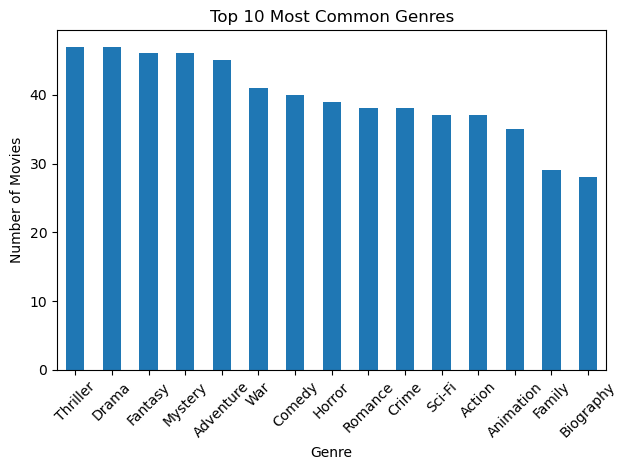

In [32]:
merged_data['genre'].value_counts().plot(kind='bar')
plt.title('Top 10 Most Common Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

__IMDB Ratings Analysis__

In [56]:
#analysing the imdb ratings
avg_imdb_ratings=merged_data['IMDB_rating'].mean().round(2)
avg_imdb_ratings
int(avg_imdb_ratings)

7

In [34]:
#top 10 highly rated movies
print(
    merged_data[['movie_name', 'IMDB_rating']]
    .sort_values('IMDB_rating', ascending=False)
    .head(10)
)

           movie_name  IMDB_rating
490     Crimson Story          9.4
463        Deep Dream          9.4
287  Forgotten Shadow          9.4
11    The Last Escape          9.4
134       Beyond Road          9.4
196     Golden Future          9.3
67      Hidden Shadow          9.2
559       Urban World          9.2
406    American Truth          9.2
175       Final Night          9.1


In [35]:
#analyze ratings by genre
genre_rating=merged_data.groupby('genre')['IMDB_rating'].mean().sort_values(ascending=False)
genre_rating

genre
Horror       7.299454
Crime        7.281579
Fantasy      7.217391
Mystery      7.214986
Drama        7.206383
Thriller     7.178723
War          7.170732
Adventure    7.079527
Sci-Fi       7.026739
Family       6.996552
Biography    6.996429
Animation    6.928267
Action       6.921334
Romance      6.910526
Comedy       6.872500
Name: IMDB_rating, dtype: float64

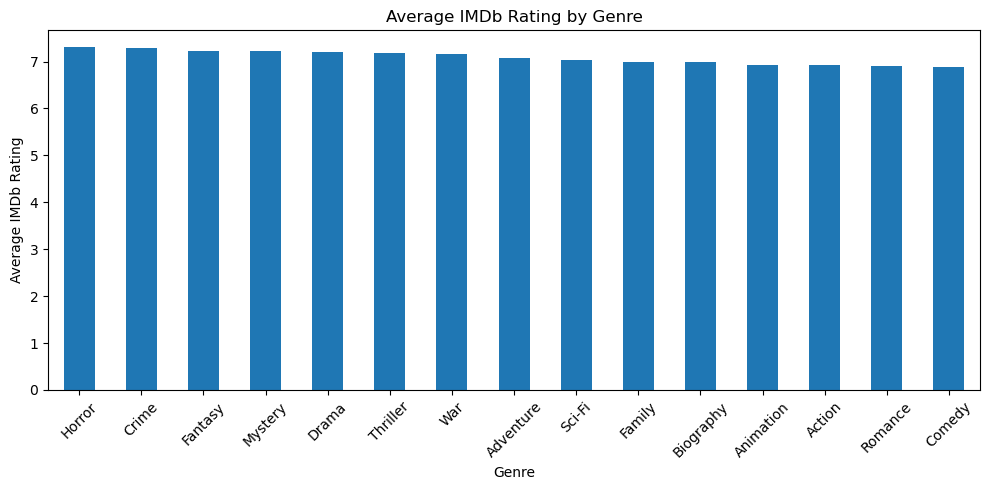

In [36]:
genre_rating.plot(kind='bar', figsize=(10, 5))
plt.title('Average IMDb Rating by Genre')
plt.xlabel('Genre')
plt.ylabel('Average IMDb Rating')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

__Runtime Analysis__

In [37]:
#analysing runtime
print("Average runtime:", merged_data['runtime'].mean())
print("Shortest runtime:", merged_data['runtime'].min())
print("Longest runtime:", merged_data['runtime'].max())

Average runtime: 127.6593220338983
Shortest runtime: 80.0
Longest runtime: 204.0


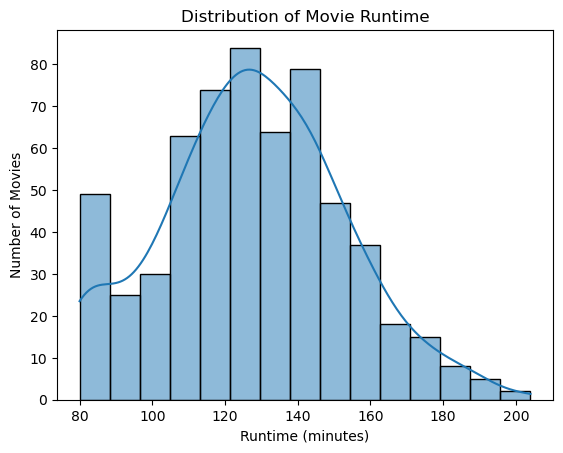

In [52]:
sns.histplot(data=merged_data, x='runtime', bins=15, kde=True)
plt.title('Distribution of Movie Runtime')
plt.xlabel('Runtime (minutes)')
plt.ylabel('Number of Movies')
plt.show()

__Gross Income Analysis__

In [79]:
#analysing gross income
top_revenues = merged_data.nlargest(10, 'gross_income',)[
    ['movie_name', 'genre', 'IMDB_rating', 'gross_income']
]
print(top_revenue)

           movie_name      genre  IMDB_rating  gross_income
519    Northern World    Fantasy          7.8   118355962.0
431     Indian Escape   Thriller          7.9   111175536.0
454        Royal Road   Thriller          7.4    40348557.0
590     Perfect Story     Sci-Fi          7.2    34312966.0
187     Golden Shadow      Drama          7.5    34168976.0
110        Lost Story    Romance          7.4    33287862.0
569    Dangerous Hope  Animation          7.1    31903502.0
536   Southern Future    Mystery          7.9    30565566.0
413  American Kingdom   Thriller          8.0    30047492.0
286   Forgotten Truth     Action          6.5    29592801.0


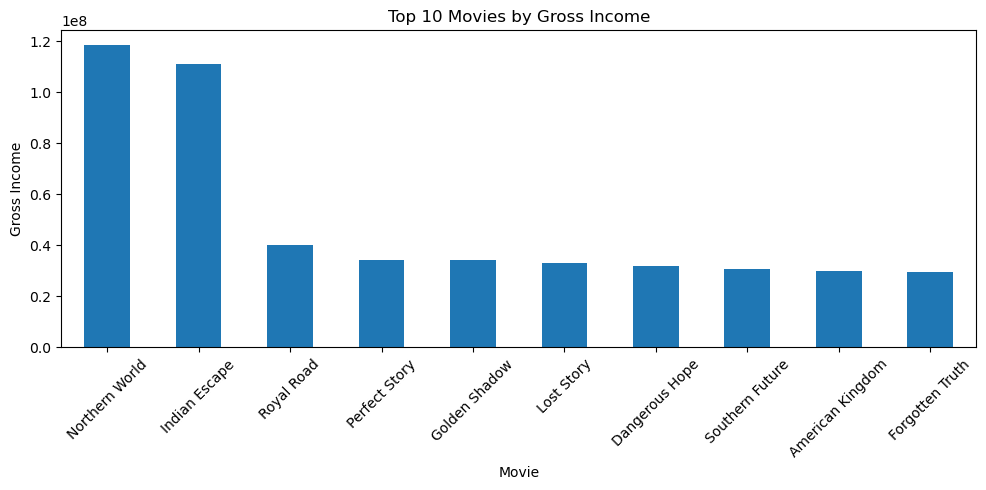

In [44]:
top_revenue.plot(
    x='movie_name',
    y='gross_income',
    kind='bar',
    figsize=(10, 5),
    legend=False
)

plt.title('Top 10 Movies by Gross Income')
plt.xlabel('Movie')
plt.ylabel('Gross Income')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

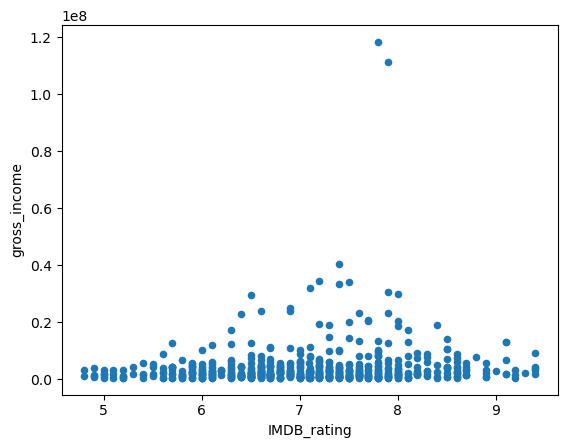

In [111]:
#analysing IMDB ratings and gross income
merged_data.plot(x='IMDB_rating', y='gross_income', kind='scatter')
plt.show()

In [103]:
#correlation between IMDB_rating and gross income
merged_data['IMDB_rating'].corr(merged_data['gross_income'])

np.float64(0.11509614236419986)

__Director Analysis__

In [89]:
#movies per director
director_counts = (
    merged_data[merged_data['Director'].notna() & (merged_data['Director'] != 'Unknown')]
    ['Director'].value_counts()
)
director_counts

Director
Brian Taylor          42
Andrew Davis          41
Peter Adams           39
William Scott         34
Anthony Wright        34
Matthew Allen         30
Kevin Lewis           29
Michael Brown         29
Richard Johnson       29
Edward Harris         28
Jonathan Moore        27
Thomas Clark          27
Steven Martin         26
Christopher Miller    25
Mark Robinson         25
James Carter          24
Daniel Thomas         24
John Walker           23
David Anderson        23
Robert Wilson         19
unknown               12
Name: count, dtype: int64

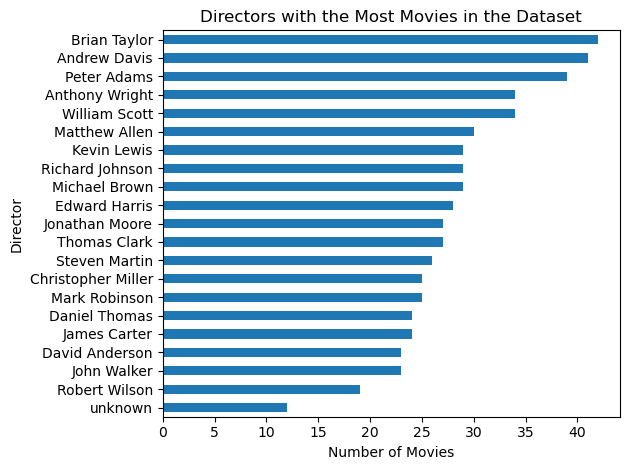

In [92]:
director_counts.sort_values().plot(kind='barh', )
plt.title('Directors with the Most Movies in the Dataset')
plt.xlabel('Number of Movies')
plt.ylabel('Director')
plt.tight_layout()
plt.show()

In [81]:
#top 10 highly rated directors 
highly_rated_dic = merged_data.groupby('Director')['IMDB_rating'].mean().sort_values(ascending=False).head(10)
print(highly_rated_dic)

Director
Michael Brown     7.375862
Daniel Thomas     7.370833
Brian Taylor      7.342857
Steven Martin     7.284615
Anthony Wright    7.202941
Kevin Lewis       7.199633
Thomas Clark      7.196296
Mark Robinson     7.120000
Edward Harris     7.103191
Matthew Allen     7.099645
Name: IMDB_rating, dtype: float64


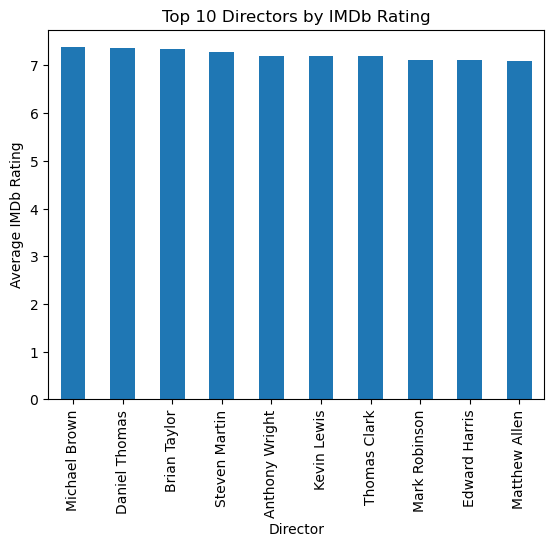

In [88]:
highly_rated_dic.plot(kind='bar', title='Top 10 Directors by IMDb Rating')
plt.ylabel('Average IMDb Rating')
plt.show()

In [94]:
#top 10 directors by gross income
top_dic_by_income = merged_data.groupby('Director')['gross_income'].mean().sort_values(ascending=False).head(10).round(2)
print(top_dic_by_income)

Director
Brian Taylor       6512091.17
Peter Adams        5746103.32
Michael Brown      5613479.12
Steven Martin      5608886.15
Unknown            5608814.80
Jonathan Moore     5486771.19
John Walker        5419488.75
Andrew Davis       4951488.88
Robert Wilson      4739999.63
Richard Johnson    4561565.36
Name: gross_income, dtype: float64


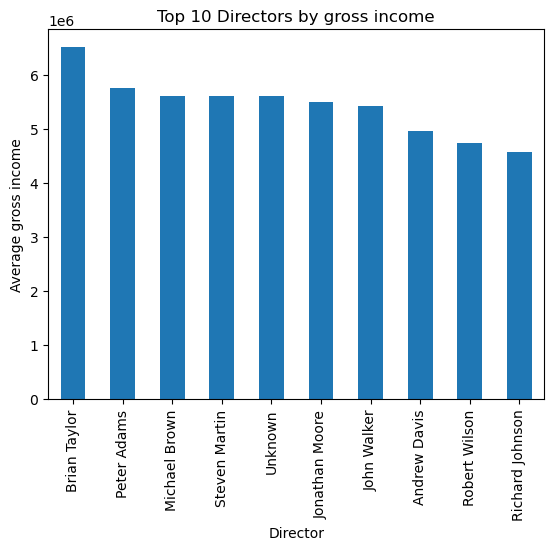

In [100]:
top_dic_by_income.plot(kind='bar', title='Top 10 Directors by gross income')
plt.ylabel('Average gross income')
plt.show()

__Hits and Flops Analysis__

In [55]:
#total counts of  hit and flop
merged_data['hit/flop'].value_counts()

hit/flop
Flop    584
Hit       8
Name: count, dtype: int64

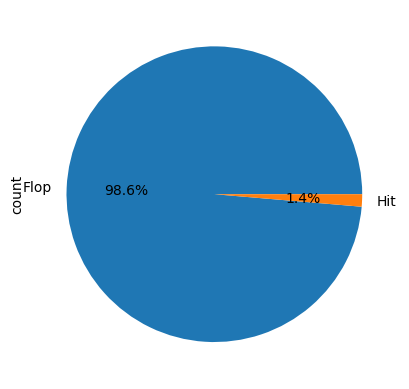

In [114]:
merged_data['hit/flop'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.show()